# Tara chl analysis

In [1]:
import geopandas as gpd
import gsw
from scipy import stats
import statsmodels.api as sm
from scipy.stats import linregress
from scipy.optimize import curve_fit
import xarray as xr
from geopy import distance
import math
import cartopy.crs as crs
from datetime import datetime
import cmocean
from cartopy.mpl.ticker import (LongitudeFormatter, LatitudeFormatter, LatitudeLocator, LongitudeLocator)
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import cartopy.crs as crs
from matplotlib.lines import Line2D
from numba import njit
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import moment
from scipy.optimize import minimize
import scipy.integrate as integrate
import matplotlib.pyplot as plt
import json
import os
import seaborn as sns
import scipy as sp
import statsmodels.api as sm
from scipy.optimize import least_squares
from sklearn.linear_model import RANSACRegressor, LinearRegression
from scipy.optimize import curve_fit
from scipy.stats import pearsonr, spearmanr
from scipy.stats import lognorm, norm 
from sklearn.mixture import GaussianMixture
from scipy.stats import gaussian_kde
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from scipy.stats import binned_statistic

In [2]:
from pathlib import Path
ROOT = Path.cwd()


Dataset

In [4]:
gdf = gpd.read_feather(ROOT/'merged_tara_pacific_microbiome_acs_160124.feather') # Download the file from Zenodo
gdf['sigma'] = gsw.sigma0(gdf.s, gdf.t)

get_dist provides a vector of distances in km between the first point of the transect and the i-th

In [5]:
def get_dist(df, df_start, flip=False):
    distances = []
    if flip == False:
        first_row = df_start.iloc[0]
    else:
        first_row = df_start.iloc[-1]
    for row in df.itertuples(index=False):
        distances.append(distance.distance((row.lat, row.lon),(first_row.lat,first_row.lon)).meters/1000)
    return(distances)

Detect flags

In [6]:
def is_set(x, n):
    return x & 1 << n != 0

gdf['mission_id'] = 0
gdf.loc[gdf['datetime'] > '2020-01-01', 'mission_id'] = 1

gdf['passes_flags'] = True

# find relevant flags in TaraPacific
passes_flag = []
flag_bits = [3]

for i in gdf[gdf.mission_id==0].flag_bit:
    passed = True
    for bit in flag_bits:
        if is_set(i,bit):
            passed = False
    passes_flag.append(passed)
    
passes_flag = np.array(passes_flag)

gdf.loc[gdf['mission_id'] == 0, 'passes_flags'] = passes_flag

# find relevant flags in TaraMicrobiome
passes_flag = []
flag_bits = [8,9]

for i in gdf[gdf.mission_id==1].flag_bit:
    passed = True
    for bit in flag_bits:
        if is_set(i,bit):
            passed = False
    passes_flag.append(passed)
    
passes_flag = np.array(passes_flag)

gdf.loc[gdf['mission_id'] == 1, 'passes_flags'] = passes_flag

gdf = gdf[gdf.passes_flags==True]

Datatime format

In [7]:
# Ensure datetime is in proper format
gdf["datetime"] = pd.to_datetime(gdf["datetime"])

# Sort by datetime
gdf = gdf.sort_values("datetime").reset_index(drop=True)

In [8]:
step = 1500
min_win = 5
max_win = 1500


Our model:

In [9]:

def psi(x):
    with np.errstate(over='ignore', invalid='ignore'):
        result = 1 - np.exp(-x) * np.sinh(x)/x
    result = np.where(np.isfinite(result), result, np.nan)
    return result

def patch(x, g, v):
    return v * (1 - (2*g)*psi(x/(2*g))/x)

Initializations: we explore patchiness considerng 16 intervall in log scale from 1 km to 300 km

In [10]:
win_sizes = np.unique(np.logspace(np.log10(min_win), np.log10(max_win), 16, dtype=int))
nlags = 6
window_t = 'triang'

In [9]:
# we evaluate the correlation length (xi_acf) using different number of lag-steps

def analyze_xi_vs_lags(
    gdf,
    step=1500,
    min_lag=3,
    max_lag=30
):
    
    lag_range = np.arange(min_lag, max_lag + 1)
    n_lags = len(lag_range)

    xi_matrix = []
    xi_err_matrix = []

    lat_list = []
    lon_list = []
    max_dist_list = []
    seconds_elapsed_list = []

    n_rows = len(gdf)
    start = 0

    while start + step <= n_rows:
        stop = start + step
        gdf_subset = gdf.iloc[start:stop]

     
        # coordinates
        lat_list.append(gdf_subset.lat.mean())
        lon_list.append(gdf_subset.lon.mean())

        seconds_elapsed_list.append(
            (gdf_subset.datetime.iloc[-1] - gdf_subset.datetime.iloc[0]).total_seconds()
        )

        max_dist_list.append(np.max(get_dist(gdf_subset, gdf_subset)))

        
        # ACF
        chl_values = gdf_subset['Chl_lineheight'].values

        xi_vals = []
        xi_err_vals = []

        if np.sum(np.isfinite(chl_values)) > 2:


            for nlags in lag_range:

                acf_vals = sm.tsa.stattools.acf(
                    chl_values,
                    nlags=nlags,
                    missing='drop'
                    )

                acf_fit = acf_vals[1:] 
                lag = np.arange(1, nlags+1)
                mask = acf_fit > 0

                if np.sum(mask) > 2:
                    reg = linregress(lag[mask], np.log(acf_fit[mask]))
                    slope = reg.slope
                    slope_err = reg.stderr

                    xi = -1 / slope if slope != 0 else np.nan
                    xi_err = slope_err / (slope**2) if slope != 0 else np.nan
                else:
                    xi = np.nan
                    xi_err = np.nan

                xi_vals.append(xi)
                xi_err_vals.append(xi_err)

        else:
            xi_vals = [np.nan] * n_lags
            xi_err_vals = [np.nan] * n_lags

        xi_matrix.append(xi_vals)
        xi_err_matrix.append(xi_err_vals)

        start = stop


    df_out = pd.DataFrame({
        "lat": lat_list,
        "lon": lon_list,
        "max_dist": max_dist_list,
        "seconds_elapsed": seconds_elapsed_list,
        **{f"xi_lag_{lag}": [row[i] for row in xi_matrix]
           for i, lag in enumerate(lag_range)},
        **{f"xi_err_lag_{lag}": [row[i] for row in xi_err_matrix]
           for i, lag in enumerate(lag_range)}
    })

    return df_out


In [ ]:
lags_df=analyze_xi_vs_lags(
    gdf,
    step=1500,
    min_lag=3,
    max_lag=30
)
lags_df.head()

,lat,lon,max_dist,seconds_elapsed,xi_lag_3,xi_lag_4,xi_lag_5,xi_lag_6,xi_lag_7,xi_lag_8,...,xi_err_lag_21,xi_err_lag_22,xi_err_lag_23,xi_err_lag_24,xi_err_lag_25,xi_err_lag_26,xi_err_lag_27,xi_err_lag_28,xi_err_lag_29,xi_err_lag_30
0,44.779989,-10.803328,401.008057,124439.0,198.048797,184.683074,174.477782,165.909492,159.342004,153.830238,...,2.061239,1.928521,1.813544,1.713654,1.625428,1.549451,1.487690,1.437440,1.393914,1.350619
1,42.600590,-14.883883,391.668318,113400.0,180.059326,177.649928,163.500510,149.912030,139.516637,131.926197,...,2.276788,2.134939,2.004350,1.895697,1.806135,1.729724,1.663329,1.603477,1.546134,1.488865
2,40.199694,-18.621962,411.206162,113521.0,148.341901,147.249619,143.988783,134.016062,128.145073,125.060682,...,0.763452,0.695126,0.636025,0.602177,0.582637,0.619950,0.656550,0.686771,0.761323,0.865361
3,38.189880,-22.227516,353.457221,120240.0,38.755612,44.912006,48.901881,49.077397,48.057565,46.812415,...,0.604274,0.671918,0.747458,0.840564,0.937105,0.994227,1.039336,1.113517,1.229801,1.331100
4,37.239355,-25.563827,271.947799,126000.0,244.549743,228.021499,215.560136,206.586757,199.547619,194.111552,...,2.793085,3.097281,3.406978,3.686795,3.937443,4.152426,4.329648,4.470225,4.584554,4.643200


In [11]:
lags = lags_df[lags_df.max_dist < 1000]      # < 3 x mean(max_dist)
lags = lags[lags.max_dist > 50]        # > 1/5 x mean(max_dist)
lags = lags[lags.seconds_elapsed < 1500*60*3]     # 60*1500 = expected time
lags = lags[lags.seconds_elapsed > 1500*60/5] 

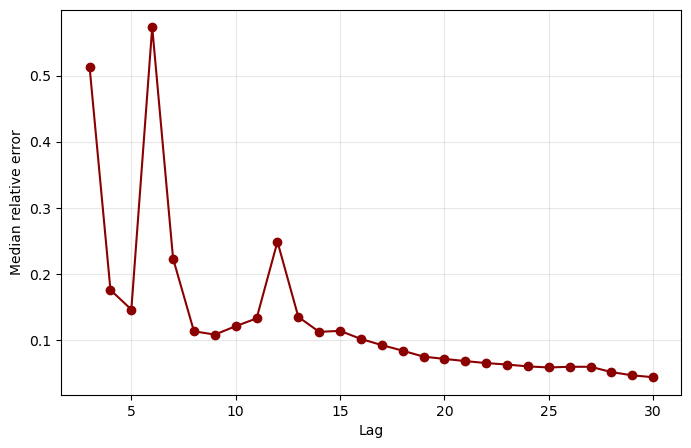

In [12]:
lag_cols = [f"xi_lag_{i}" for i in range(3, 31)]  # da lag 3 a 30
lag_err = [f"xi_err_lag_{i}" for i in range(3, 31)]  # da lag 3 a 30
# Estrai i valori xi in un array (transect x lag)
xi_values = (lags[lag_err].to_numpy())/(lags[lag_cols].to_numpy())


xi_values_masked = np.where(xi_values > 0, xi_values, np.nan)


median_xierr = np.nanmean(xi_values_masked, axis=0)

plt.figure(figsize=(8,5))
plt.plot(range(3,31), median_xierr, marker='o', color='darkred')
plt.xlabel("Lag")
plt.ylabel("Median relative error")
plt.grid(alpha=0.3)
plt.show()
# After this check, we take lag=6


Fitting distributions:

In [ ]:
def patch_residuals(params, x, y):
    g, v = params
    y_pred = patch(x, g, v)
    mask = y_pred > 0
    return np.log(y_pred[mask]) - y[mask]


def logSAD(n, b, c, mu):
    n = np.maximum(n, 1e-12)
    kv_val = sp.special.kv(1 - 2*mu, 2*np.sqrt(b/c))
    if kv_val <= 0 or not np.isfinite(kv_val):
        return -np.inf * np.ones_like(n)
    return ((0.5 - mu)*np.log(b*c) - b/n - n/c - (2.0 - 2.0*mu)*np.log(n) - np.log(2) - np.log(kv_val))

def loglik_GIG(params, vecN):
    b, c, mu = params
    return -np.sum(logSAD(vecN, b, c, mu))

def fit_GIG(vecN):
    vecN = vecN[vecN > 0]
    p0 = [1e-1, 1e3, 1]
    res = sp.optimize.minimize(loglik_GIG, p0, args=(vecN,),
                               bounds=[(1e-5, 0.5), (1, None), (-1.2, 2)],
                               method="Nelder-Mead", options={'maxiter': 5000})
    if res.success:
        return res.x, res.fun
    return None, None

def logLognorm(n, mu, sigma):
    n = np.maximum(n, 1e-12)
    return -np.log(n * sigma * np.sqrt(2 * np.pi)) - ((np.log(n) - mu)**2) / (2 * sigma**2)

def loglik_Lognorm(params, vecN):
    mu, sigma = params
    return -np.sum(logLognorm(vecN, mu, sigma))

def fit_Lognorm(vecN):
    vecN = vecN[vecN > 0]
    log_vecN = np.log(vecN)
    p0 = [np.mean(log_vecN), np.std(log_vecN) + 1e-3]
    res = sp.optimize.minimize(loglik_Lognorm, p0, args=(vecN,),
                               bounds=[(None, None), (1e-5, None)],
                               method="Nelder-Mead", options={'maxiter': 5000})
    if res.success:
        return res.x, res.fun
    return None, None


We introduce our function to analyze the dataset:

In [14]:
def analyze_transects(
    gdf,
    step=1500,
    min_win=5,
    max_win=1500,
    n_win_sizes=16,
    nlags=6,
    window_t='triang',
    n_acf_save=100,
    mean_dist_per_leg=1
):
    win_sizes = np.unique(
        np.logspace(np.log10(min_win), np.log10(max_win), n_win_sizes, dtype=int)
    )

    n_rows = len(gdf)
    start = 0
    results_list = [] 
    
    # here we split the dataset in several transects of size max_win, then we analyze the variance and test our model analyzing each subsample
    while start + step <= n_rows:
        stop = start + step
        gdf_subset = gdf.iloc[start:stop]
        
        chl_values = gdf_subset['Chl_lineheight'].values
        chl_pos = chl_values[np.isfinite(chl_values) & (chl_values > 0)]

        row_res = { 
            # geographical info
            "lat": gdf_subset.lat.mean(), 
            "lon": gdf_subset.lon.mean(),
            "seconds_elapsed": (gdf_subset.datetime.iloc[-1] - gdf_subset.datetime.iloc[0]).total_seconds(),
            "max_dist": np.max(get_dist(gdf_subset, gdf_subset)),
            "max_window": len(gdf_subset),
            "median": np.nanmedian(chl_pos) if len(chl_pos) > 0 else np.nan,
            "varloc": np.nan,
            "p_slope": np.nan, "xi_acf": np.nan, "gamma_hat": np.nan, "v_hat": np.nan,
            "chi2_linear": np.nan, "chi2_pat": np.nan, "R2lin": np.nan, "R2pat": np.nan,
            "ll_linear": np.nan, "ll_pat": np.nan, 
            "delta_bic": np.nan, "best_fit": "None",
            "Delta": np.nan, "best_fit_norm": "None" 
        }

        for win in win_sizes:
            row_res[f"var_win_{win}"] = np.nan
        for i in range(n_acf_save):
            row_res[f"acf_lag_{i+1}"] = np.nan

        # the local variance (varloc) is estimated taking 3 samples
        roll_var3 = gdf_subset['Chl_lineheight'].rolling(3, center=True).var()
        roll_var3 = roll_var3[np.isfinite(roll_var3) & (roll_var3 > 0)]
        if roll_var3.size > 0:
            row_res["varloc"] = roll_var3.mean()

        chla_var_loc = []
        valid_idx = []

        for i, window_s in enumerate(win_sizes):
            roll_var = gdf_subset['Chl_lineheight'].rolling(window_s, win_type=window_t, center=True).var().to_numpy()
            roll_var = roll_var[np.isfinite(roll_var) & (roll_var > 0)]
            if roll_var.size > 0:
                mean_var = roll_var.mean()
                chla_var_loc.append(mean_var)
                valid_idx.append(i)
                row_res[f"var_win_{window_s}"] = mean_var

        if len(chla_var_loc) >= 3:
            chla_var_loc = np.array(chla_var_loc)
            ln_win_dist_valid = np.log(win_sizes[valid_idx] * mean_dist_per_leg)
            ylin = np.log(chla_var_loc)
            mask = np.isfinite(ylin)

            # R2 test for the linear fit of var vs distance in log-log scale
            if np.sum(mask) > 2:
                slope_real, intercept_real = np.polyfit(ln_win_dist_valid[mask], ylin[mask], 1)
                row_res["p_slope"] = slope_real
                
                y_fit_linear = slope_real * ln_win_dist_valid + intercept_real
                chi2_lin = np.sum((ylin - y_fit_linear) ** 2)
                row_res["chi2_linear"] = chi2_lin
                sstot = np.sum((ylin - np.nanmean(ylin)) ** 2)
                
                if sstot > 0:
                    row_res["R2lin"] = 1 - (chi2_lin / sstot)
                row_res["ll_linear"] = -0.5 * chi2_lin

            if len(chl_pos) > 2:
                acf_vals = sm.tsa.stattools.acf(chl_values, nlags=n_acf_save, missing='drop')
                
                for i in range(min(n_acf_save, len(acf_vals)-1)):
                    row_res[f"acf_lag_{i+1}"] = acf_vals[i+1]
                    
                acf_fit = acf_vals[1:nlags+1]
                lag = np.arange(1, nlags+1)
                mask_acf = acf_fit > 0
                if np.sum(mask_acf) > 1:
                    row_res["xi_acf"] = -1 / linregress(lag[mask_acf], np.log(acf_fit[mask_acf]))[0]
            
            # here we fit our patch function
            x_fit = np.exp(ln_win_dist_valid)
            if len(x_fit) > 2:
                try:
                    g0 = 100
                    v0 = np.exp(np.median(ylin[:3]))
                    
                    res = least_squares(
                        patch_residuals,
                        x0=[g0, v0],
                        bounds=([1e-6, 1e-6], [np.inf, 100]),
                        args=(x_fit, ylin)
                    )
                    gamma_hat, v_hat = res.x
                    y_fit_pat = patch(x_fit, gamma_hat, v_hat)
                    mask_pos = y_fit_pat > 0

                    # R2 test for the log var vs log distance plot using the pat function
                    if np.any(mask_pos):
                        chi2_pat = np.sum((ylin[mask_pos] - np.log(y_fit_pat[mask_pos])) ** 2)
                        ssfit = np.sum((ylin[mask_pos] - np.mean(ylin[mask_pos])) ** 2)
                        
                        row_res["gamma_hat"] = gamma_hat
                        row_res["v_hat"] = v_hat
                        row_res["chi2_pat"] = chi2_pat
                        if ssfit > 0:
                            row_res["R2pat"] = 1 - chi2_pat / ssfit
                        row_res["ll_pat"] = -0.5 * chi2_pat
                except:
                    pass 
            
            n_samples = len(chl_pos)
            if n_samples >= 5:
                bic_gig, bic_lognorm, bic_gauss = np.nan, np.nan, np.nan
                
                # Fit GIG for total biomass
                popt_gig, nll_gig = fit_GIG(chl_pos)
                if popt_gig is not None:
                    bic_gig = 3 * np.log(n_samples) + 2 * nll_gig
                
                # Fit Lognormal 
                popt_log, nll_log = fit_Lognorm(chl_pos)
                if popt_log is not None:
                    bic_lognorm = 2 * np.log(n_samples) + 2 * nll_log
                
                # Fit Gaussian distribution 
                try:
                    mu_g, std_g = norm.fit(chl_pos)
                    nll_gauss = -np.sum(norm.logpdf(chl_pos, loc=mu_g, scale=std_g))
                    bic_gauss = 2 * np.log(n_samples) + 2 * nll_gauss
                except:
                    pass

                # Delta BIC: GIG vs Lognormale
                if not np.isnan(bic_gig) and not np.isnan(bic_lognorm):
                    delta_bic = bic_lognorm - bic_gig
                    row_res["delta_bic"] = delta_bic
                    row_res["best_fit"] = "Lognorm" if delta_bic < 0 else "GIG"

                # Delta BIC: Gaussian vs Lognormal
                if not np.isnan(bic_gauss) and not np.isnan(bic_lognorm):
                    Delta = bic_lognorm - bic_gauss
                    row_res["Delta"] = Delta
                    row_res["best_fit_norm"] = "Lognorm" if Delta < 0 else "Gaussian"

        results_list.append(row_res)
        start = stop

    f_out = pd.DataFrame(results_list)
    return f_out

Generate the output:

In [ ]:
df_results = analyze_transects(
    gdf,
    step=1500,
    min_win=5,
    max_win=1500,
    nlags=6
)
df_results.head()

,lat,lon,seconds_elapsed,max_dist,max_window,median,varloc,p_slope,xi_acf,gamma_hat,...,acf_lag_91,acf_lag_92,acf_lag_93,acf_lag_94,acf_lag_95,acf_lag_96,acf_lag_97,acf_lag_98,acf_lag_99,acf_lag_100
0,44.779989,-10.803328,124439.0,401.008057,1500,0.242704,0.000137,0.913909,165.909492,276.789102,...,0.356885,0.351064,0.345263,0.339462,0.333656,0.327834,0.322031,0.316239,0.310337,0.304456
1,42.600590,-14.883883,113400.0,391.668318,1500,0.363408,0.000077,0.804711,149.912030,152.339171,...,0.426799,0.423963,0.421232,0.418507,0.416482,0.413789,0.411683,0.409210,0.407228,0.405452
2,40.199694,-18.621962,113521.0,411.206162,1500,0.366999,0.000113,0.770365,134.016062,168.378385,...,0.574424,0.571504,0.568167,0.564250,0.560532,0.557475,0.553916,0.550662,0.546626,0.542877
3,38.189880,-22.227516,120240.0,353.457221,1500,0.125456,0.000072,0.474397,49.077397,25.160442,...,0.231095,0.225704,0.220730,0.218650,0.213787,0.211143,0.205473,0.201994,0.195188,0.192151
4,37.239355,-25.563827,126000.0,271.947799,1500,0.110565,0.000517,1.009065,206.586757,1993.658434,...,0.597690,0.591941,0.585971,0.579699,0.573306,0.566863,0.560445,0.553997,0.547324,0.540910


In [11]:
# load the saved file from the folder
df_results = pd.read_feather(ROOT/"patch.feather")

We consider only transects which satisfy the following condizionts:

In [12]:
gdf_filter = df_results[df_results.max_window == 1500]
gdf_filter = gdf_filter[gdf_filter.max_dist < 1000]      # < 3 x mean(max_dist)
gdf_filter = gdf_filter[gdf_filter.max_dist > 50]        # > 1/5 x mean(max_dist)
gdf_filter = gdf_filter[gdf_filter.seconds_elapsed < 1500*60*3]     # 60*1500 = expected time
gdf_filter = gdf_filter[gdf_filter.seconds_elapsed > 1500*60/5]     # 60*1500 = expected time


First we check if all transects show a lognormal;

45
243


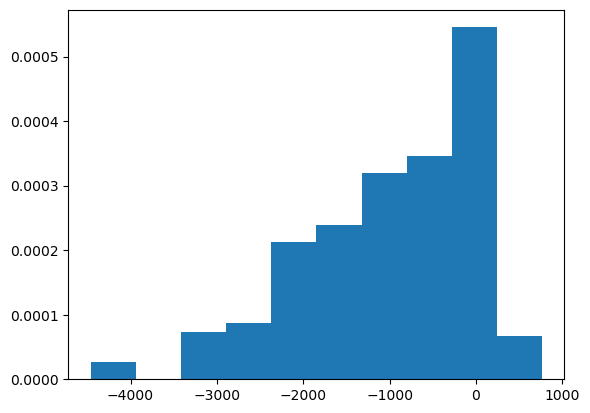

In [13]:
plt.hist(gdf_filter['delta_bic'].values,density='true')
print((gdf_filter['delta_bic']>5).sum())
print((gdf_filter['delta_bic']<5).sum())


We remove transects where we cannot measure patchiness: R2<0.4 for both linear and pat fit

In [14]:
mask = (
    (gdf_filter['R2lin'] > 0.4) | (gdf_filter['R2pat'] > 0.4)
)  & np.isfinite(gdf_filter['p_slope']) & (gdf_filter['median'] > 0) & (gdf_filter['xi_acf'] > 0) & (gdf_filter['varloc'] > 0)

df = gdf_filter[mask].copy()        # new file
df.loc[:,'log_xi'] = np.log(df['xi_acf'])       # we add log scales and R2ratio
df.loc[:,'ratio'] = df['R2pat']/df['R2lin']
xi = df['xi_acf'].values
p_slope = df['p_slope'].values
log_xi = np.log(xi).reshape(-1, 1)


We test the correlation between the patchiness parameter p derived fitting log(var) vs log(L) with a linear function, and the correlation length fitted using ACF:

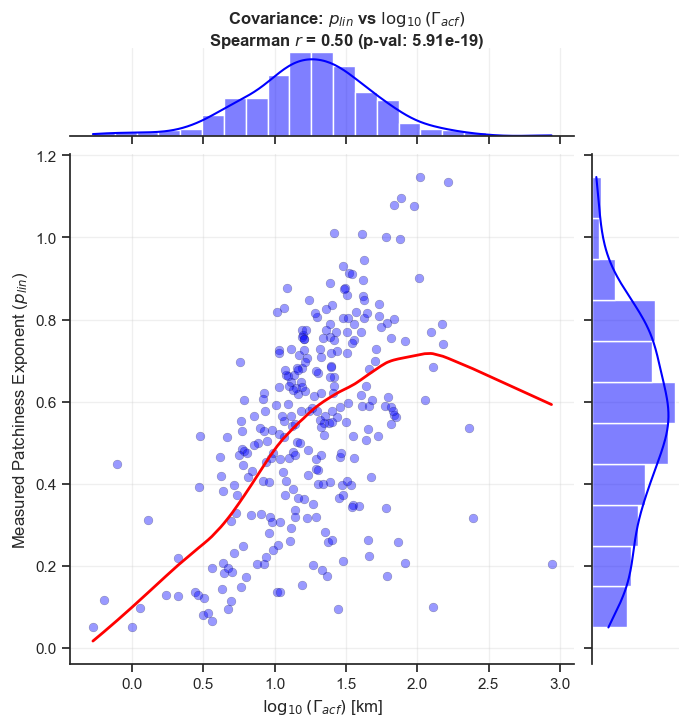

In [15]:
sns.set_theme(style="ticks", rc={"axes.grid": True, "grid.alpha": 0.3})

df_plot = df.copy()
df_plot['log_xi_acf'] = np.log10(df_plot['xi_acf']*0.2)
df_plot['log_gamma_hat'] = np.log10(df_plot['gamma_hat']*0.2)

# filter negative values
df_plot = df_plot.dropna(subset=['log_xi_acf', 'log_gamma_hat', 'p_slope'])
df_plot = df_plot[np.isfinite(df_plot['log_xi_acf']) & np.isfinite(df_plot['log_gamma_hat'])]

# Spearman correlation
corr_p_xi, p_val_1 = spearmanr(df_plot['log_xi_acf'], df_plot['p_slope'])

g1 = sns.jointplot(
    data=df_plot,
    x='log_xi_acf',
    y='p_slope',
    kind='reg',
    color='blue',
    lowess=True,
    scatter_kws={'alpha': 0.4, 'edgecolor': 'k', 'linewidth': 0.3, 's': 40},
    line_kws={'color': 'red', 'linewidth': 2}, 
    height=7
)

g1.set_axis_labels(r'$\log_{10}(\Gamma_{acf})$ [km]', r'Measured Patchiness Exponent ($p_{lin}$)', fontsize=12)
g1.fig.suptitle(rf'Covariance: $p_{{lin}}$ vs $\log_{{10}}(\Gamma_{{acf}})$' '\n' rf'Spearman $r$ = {corr_p_xi:.2f} (p-val: {p_val_1:.2e})', 
                fontsize=12, fontweight='bold', y=1.03)

plt.show()

Here we compare the correlation lenght obtained by the acf and fitting patch function

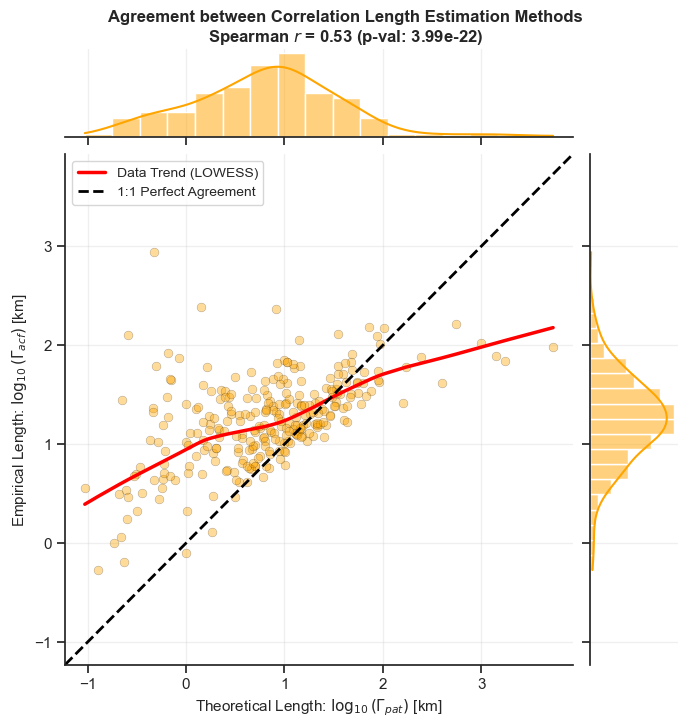

In [16]:
# Calculate Spearman correlation for the two correlation lengths
corr_lengths, p_val_2 = spearmanr(df_plot['log_gamma_hat'], df_plot['log_xi_acf'])


min_val = min(df_plot['log_gamma_hat'].min(), df_plot['log_xi_acf'].min()) - 0.2
max_val = max(df_plot['log_gamma_hat'].max(), df_plot['log_xi_acf'].max()) + 0.2
limits = [min_val, max_val]


g = sns.jointplot(
    data=df_plot,
    x='log_gamma_hat',
    y='log_xi_acf',
    kind='reg',
    color='orange', 
    lowess=True,   
    scatter_kws={'alpha': 0.4, 'edgecolor': 'k', 'linewidth': 0.3, 's': 40},
    line_kws={'color': 'red', 'linewidth': 2.5, 'label': 'Data Trend (LOWESS)'},
    height=7,
    xlim=limits,
    ylim=limits
)


ax_joint = g.ax_joint
ax_joint.plot(limits, limits, color='black', linestyle='--', linewidth=2, label='1:1 Perfect Agreement')
ax_joint.legend(frameon=True, loc='upper left', fontsize=10)
g.set_axis_labels(r'Theoretical Length: $\log_{10}(\Gamma_{pat})$ [km]', 
                  r'Empirical Length: $\log_{10}(\Gamma_{acf})$ [km]', fontsize=11)

g.fig.suptitle(r'Agreement between Correlation Length Estimation Methods' + 
               f'\nSpearman $r$ = {corr_lengths:.2f} (p-val: {p_val_2:.2e})', 
               fontsize=12, fontweight='bold', y=1.03)

plt.show()

Now we compare the p slope obtained fitting the patch function using the correlation length measured by ACF

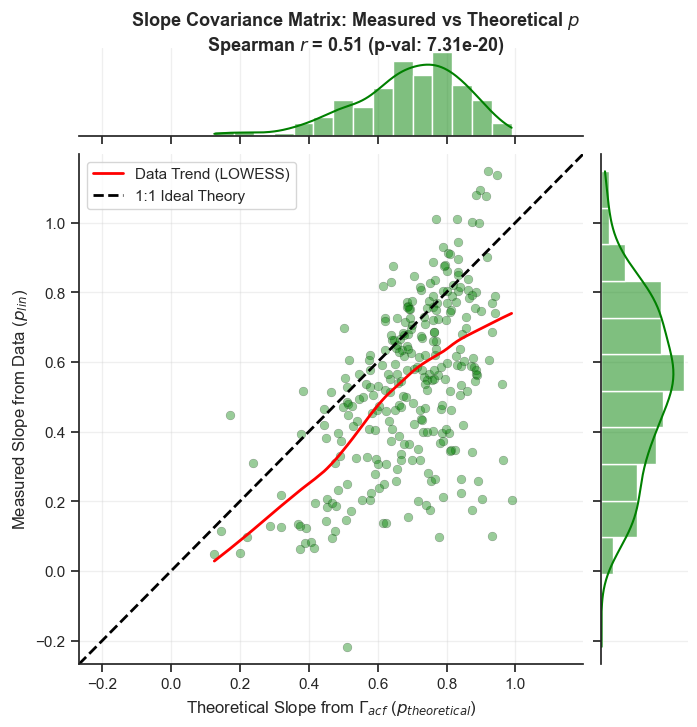

In [17]:
win_sizes = np.unique(np.logspace(np.log10(5), np.log10(1500), 16, dtype=int))
df_analysis = df.copy()
p_theoretical_list = []

for idx, row in df_analysis.iterrows():
    g = row['xi_acf']
    if not np.isfinite(g) or g <= 0:
        p_theoretical_list.append(np.nan)
        continue
    # Generate theoretical patch values (v=1 preserves the slope in log-log)
    patch_vals = patch(win_sizes, g, v=1)
    
    mask = (patch_vals > 0) & np.isfinite(patch_vals)
    if np.sum(mask) > 2:
        slope, _ = np.polyfit(np.log(win_sizes[mask]), np.log(patch_vals[mask]), 1)
        p_theoretical_list.append(slope)
    else:
        p_theoretical_list.append(np.nan)
df_analysis['p_theoretical'] = p_theoretical_list


df_analysis = df_analysis.dropna(subset=['p_slope', 'p_theoretical', 'xi_acf'])
df_analysis['log_xi_acf'] = np.log10(df_analysis['xi_acf'])

# Calculate Spearman correlation 
slope_corr, p_val_slope = spearmanr(df_analysis['p_theoretical'], df_analysis['p_slope'])


g = sns.jointplot(
    data=df_analysis,
    x='p_theoretical',
    y='p_slope',
    kind='reg',
    color='green',
    lowess=True,     
    scatter_kws={'alpha': 0.4, 'edgecolor': 'k', 'linewidth': 0.3, 's': 40},
    line_kws={'color': 'red', 'linewidth': 2, 'label': 'Data Trend (LOWESS)'},
    height=7
)

ax_joint = g.ax_joint
min_val = min(df_analysis['p_theoretical'].min(), df_analysis['p_slope'].min()) - 0.05
max_val = max(df_analysis['p_theoretical'].max(), df_analysis['p_slope'].max()) + 0.05
ax_joint.plot([min_val, max_val], [min_val, max_val], color='black', linestyle='--', linewidth=2, label='1:1 Ideal Theory')
ax_joint.set_xlim(min_val, max_val)
ax_joint.set_ylim(min_val, max_val)
ax_joint.legend(frameon=True, loc='upper left')

g.set_axis_labels(r'Theoretical Slope from $\Gamma_{acf}$ ($p_{theoretical}$)', r'Measured Slope from Data ($p_{lin}$)', fontsize=12)
g.fig.suptitle(f'Slope Covariance Matrix: Measured vs Theoretical $p$\nSpearman $r$ = {slope_corr:.2f} (p-val: {p_val_slope:.2e})', 
                fontsize=13, fontweight='bold', y=1.03)
plt.show()

# Cluster analysis: oligotrophic vs upwelling regions

From the analysis just carried out, we can see an excellent correlation between the correlation lengths fitted in different ways, the estimates of p, and  p vs correlation length. However, we can see that there is a lot of noise for small values of Gamma_ACFand p_lin. We check if the more scattered points can be attributed to a noise cluster. To do this, we use GMM clustering, using p_lin and Gamma_ACF as references, to identify the cluster where there is a correlation between patchiness and correlation length

In [18]:
df_clean = df_analysis.copy()
X = np.column_stack([
    df_clean['p_slope'].values,
    np.log(df_clean['xi_acf'].values)
])

mask = np.all(np.isfinite(X), axis=1)
X_clean = X[mask]
df_clean = df_clean[mask].copy()

gmm = GaussianMixture(n_components=2, covariance_type='full', random_state=42)
gmm.fit(X_clean)
clusters = gmm.predict(X_clean)
df_clean['cluster'] = clusters

# The main cluster should be the one with more points and higher covariance
main_cluster_id = np.argmax(np.bincount(clusters))
df_main_cluster = df_clean[df_clean['cluster'] == main_cluster_id].copy()

print(f"Main cluster ID: {main_cluster_id}")
print(f"Total points in the main cluster: {len(df_main_cluster)} out of {len(df_clean)}")

Main cluster ID: 0
Total points in the main cluster: 215 out of 282


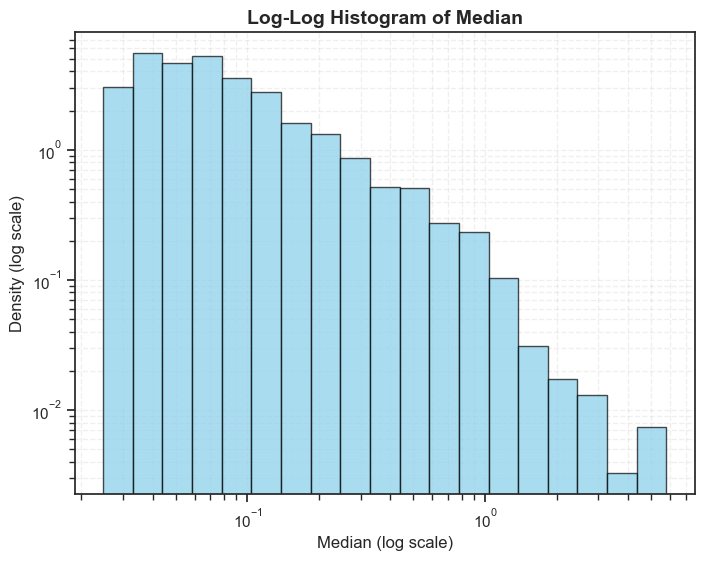

In [19]:
data = df_clean['median'].dropna().values
data = data[data > 0]

bins_log = np.logspace(np.log10(data.min()), np.log10(data.max()), 20)

plt.figure(figsize=(8, 6))


plt.hist(data, bins=bins_log, density=True, log=True, 
         color='skyblue', edgecolor='black', alpha=0.7)


plt.xscale('log')


plt.xlabel('Median (log scale)', fontsize=12)
plt.ylabel('Density (log scale)', fontsize=12)
plt.title('Log-Log Histogram of Median', fontsize=14, fontweight='bold')


plt.grid(True, which="both", ls="--", alpha=0.3)

plt.show()

We check the distribution of the clusters across some paramaters. In particular, we foucs on chl medinavalues, chl local variance, R2 index (Log(var) is linear with respect to Log(L) wehn R2>1, otherwise it shows the predicted double trend), different combinations of p and Gamma:

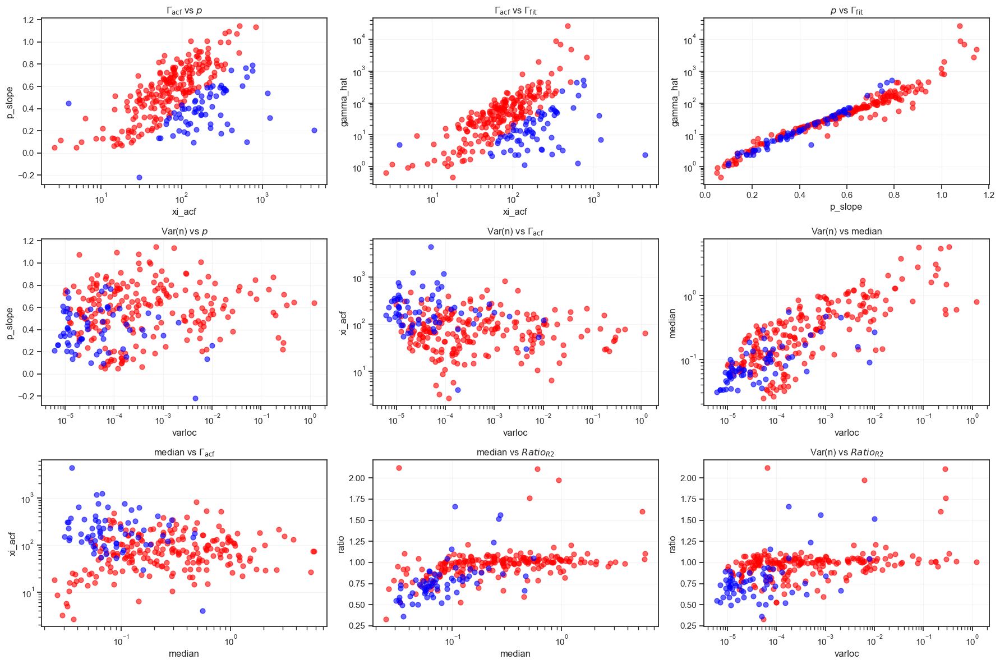

In [20]:
scatter_panels = [
    ('xi_acf', 'p_slope', r'$\Gamma_{\mathrm{acf}}$ vs $p$'),
    ('xi_acf', 'gamma_hat', r'$\Gamma_{\mathrm{acf}}$ vs $\Gamma_\mathrm{fit}$'),
    ('p_slope', 'gamma_hat', r'$p$ vs $\Gamma_\mathrm{fit}$'),
    ('varloc', 'p_slope', r'Var(n) vs $p$'),
    ('varloc', 'xi_acf', r'Var(n) vs $\Gamma_{\mathrm{acf}}$'),
    ('varloc', 'median', r'Var(n) vs median'),
    ('median', 'xi_acf', r'median vs $\Gamma_{\mathrm{acf}}$'),
    ('median', 'ratio', r'median vs $Ratio_{R2}$'),
    ('varloc', 'ratio', r'Var(n) vs $Ratio_{R2}$')
]

plt.figure(figsize=(18,12))
for i, (xcol, ycol, title) in enumerate(scatter_panels, 1):
    plt.subplot(3,3,i)
    for cluster_id, color in zip(df_clean['cluster'].unique(), ['red','blue']):
        subset = df_clean[df_clean['cluster']==cluster_id]
        plt.scatter(subset[xcol], subset[ycol], color=color, alpha=0.6, s=40)
    
    if xcol in ['xi_acf','varloc','median','gamma_hat','v_hat']:
        plt.xscale('log')
    if ycol in ['xi_acf','varloc','median','gamma_hat','v_hat']:
        plt.yscale('log')
    
    plt.xlabel(xcol)
    plt.ylabel(ycol)
    plt.title(title)
    plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()


The previous analysis indicates a dependence on xi_acf, the goodness-of-fit of the patch function, and the median of chl. To avoid ambiguities in clustering methods, we use the median of chlorophyll concentration as a parameter for our clustering: by exploring different threshold values, we choose the one for which we find two clusters analogous to those described above, namely, a main cluster where there is a high correlation between patchiness and xi_acf, and another with a spurious correlation. As we show, this threshold value is approximately 0.11 mg/m3

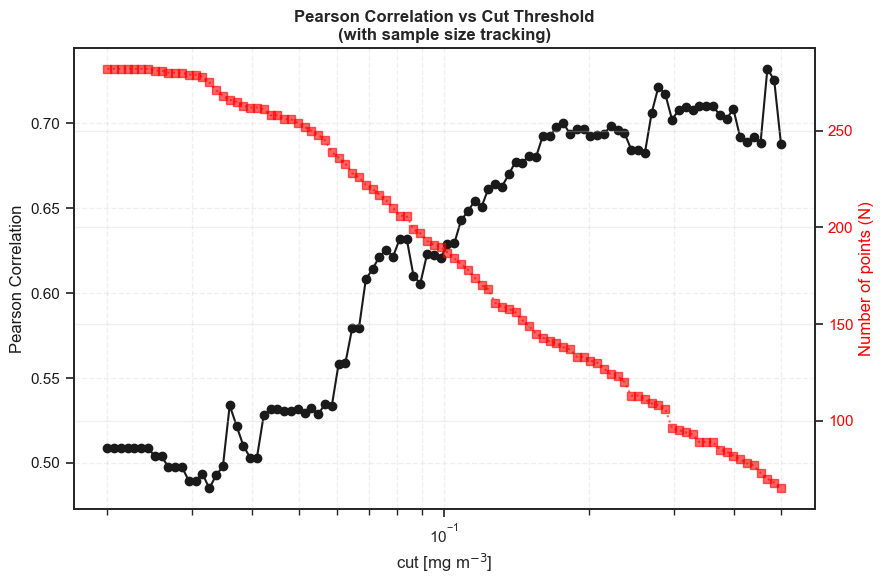

In [21]:
cuts = np.logspace(np.log10(1/50), np.log10(1/2), 100)
valid_cuts = []
correlations = []
n_points = []

for cut in cuts:
    subset = df_clean[
        (df_clean['median'] > cut) & 
        np.isfinite(df_clean['p_slope']) & 
        np.isfinite(np.log10(df_clean['xi_acf']))
    ]
    
    if len(subset) >= 10:
        corr, _ = pearsonr(subset['p_slope'], np.log10(subset['xi_acf']))
        valid_cuts.append(cut)
        correlations.append(corr)
        n_points.append(len(subset))

fig, ax1 = plt.subplots(figsize=(9, 6))

color1 = 'k'
ax1.plot(valid_cuts, correlations, marker='o', linestyle='-', color=color1)
ax1.set_xscale('log')
ax1.set_xlabel(r'cut [mg m$^{-3}$]', fontsize=12)
ax1.set_ylabel(r'Pearson Correlation', color=color1, fontsize=12)
ax1.tick_params(axis='y', labelcolor=color1)
ax1.grid(True, which="both", ls="--", alpha=0.3)

ax2 = ax1.twinx()
color2 = 'red'
ax2.plot(valid_cuts, n_points, marker='s', linestyle=':', color=color2, alpha=0.6)
ax2.set_ylabel('Number of points (N)', color=color2, fontsize=12)
ax2.tick_params(axis='y', labelcolor=color2)

plt.title('Pearson Correlation vs Cut Threshold\n(with sample size tracking)', fontweight='bold')
plt.tight_layout()
plt.show()

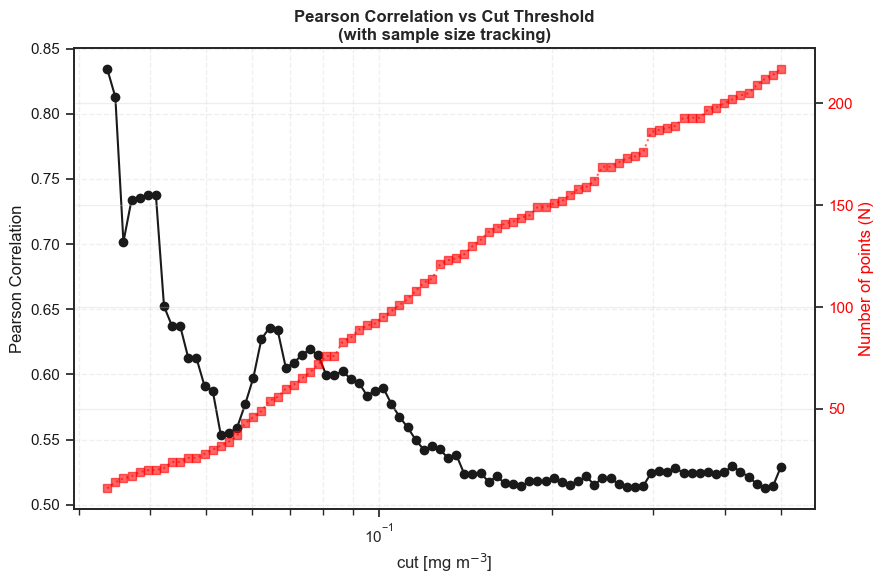

In [22]:
cuts = np.logspace(np.log10(1/50), np.log10(1/2), 100)
valid_cuts = []
correlations = []
n_points = []

for cut in cuts:
    subset = df_clean[
        (df_clean['median'] < cut) & 
        np.isfinite(df_clean['p_slope']) & 
        np.isfinite(np.log10(df_clean['xi_acf']))
    ]
    
    if len(subset) >= 10:
        corr, _ = pearsonr(subset['p_slope'], np.log10(subset['xi_acf']))
        valid_cuts.append(cut)
        correlations.append(corr)
        n_points.append(len(subset))

fig, ax1 = plt.subplots(figsize=(9, 6))

color1 = 'k'
ax1.plot(valid_cuts, correlations, marker='o', linestyle='-', color=color1)
ax1.set_xscale('log')
ax1.set_xlabel(r'cut [mg m$^{-3}$]', fontsize=12)
ax1.set_ylabel(r'Pearson Correlation', color=color1, fontsize=12)
ax1.tick_params(axis='y', labelcolor=color1)
ax1.grid(True, which="both", ls="--", alpha=0.3)

ax2 = ax1.twinx()
color2 = 'red'
ax2.plot(valid_cuts, n_points, marker='s', linestyle=':', color=color2, alpha=0.6)
ax2.set_ylabel('Number of points (N)', color=color2, fontsize=12)
ax2.tick_params(axis='y', labelcolor=color2)

plt.title('Pearson Correlation vs Cut Threshold\n(with sample size tracking)', fontweight='bold')
plt.tight_layout()
plt.show()

Comparison with random sampling

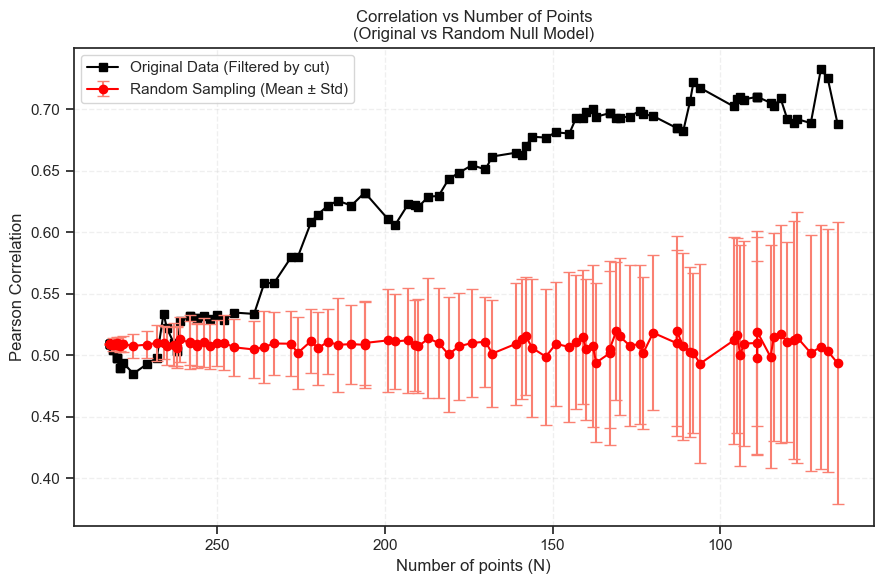

In [24]:
df_valid = df_clean[
    np.isfinite(df_clean['p_slope']) & 
    np.isfinite(np.log10(df_clean['xi_acf']))
].copy()

cuts = np.logspace(np.log10(1/50), np.log10(1/2), 100)
n_points_list = []
original_corrs = []
mean_corrs = []
std_corrs = []

for cut in cuts:
    subset = df_valid[df_valid['median'] > cut]
    N = len(subset)
    
    if N >= 10:
        orig_corr, _ = pearsonr(subset['p_slope'], np.log10(subset['xi_acf']))
        
        random_corrs = []
        for _ in range(100):
            sample = df_valid.sample(n=N, replace=False)
            r_corr, _ = pearsonr(sample['p_slope'], np.log10(sample['xi_acf']))
            random_corrs.append(r_corr)
            
        n_points_list.append(N)
        original_corrs.append(orig_corr)
        mean_corrs.append(np.mean(random_corrs))
        std_corrs.append(np.std(random_corrs))

plt.figure(figsize=(9, 6))

plt.plot(n_points_list, original_corrs, marker='s', linestyle='-', color='black', label='Original Data (Filtered by cut)')
plt.errorbar(n_points_list, mean_corrs, yerr=std_corrs, fmt='-o', color='red', ecolor='salmon', capsize=4, elinewidth=1.5, label='Random Sampling (Mean ± Std)')

plt.gca().invert_xaxis()
plt.xlabel('Number of points (N)')
plt.ylabel('Pearson Correlation')
plt.title('Correlation vs Number of Points\n(Original vs Random Null Model)')
plt.legend(loc='best')
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
df_valid = df_valid.reset_index(drop=True)

In [26]:
FIG2_TITLE_SIZE = 18
FIG2_LABEL_SIZE = 18
FIG2_TICK_SIZE = 16

def style_figure_axis(ax):
    ax.title.set_size(FIG2_TITLE_SIZE)
    ax.xaxis.label.set_size(FIG2_LABEL_SIZE)
    ax.yaxis.label.set_size(FIG2_LABEL_SIZE)
    ax.tick_params(axis="both", labelsize=FIG2_TICK_SIZE)
    return ax

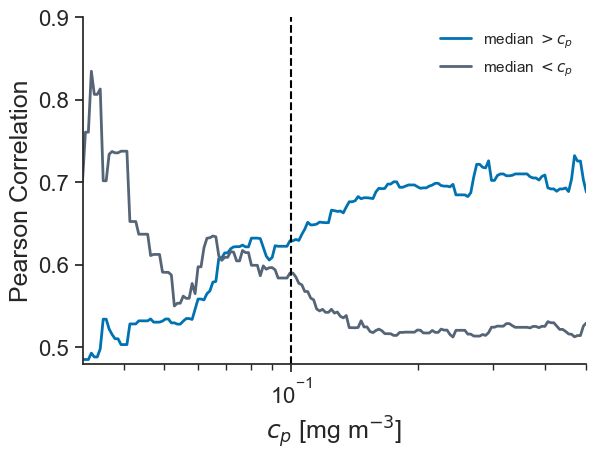

In [27]:
# 2 custers
c_main = '#0072B2'
c_second = '#556577'

cuts = np.logspace(np.log10(1/50), np.log10(1/2), 200)

valid_cuts_greater = []
corr_greater = []

valid_cuts_lesser = []
corr_lesser = []

for cut in cuts:
 
    mask_finite = np.isfinite(df_clean['p_slope']) & np.isfinite(np.log10(df_clean['xi_acf']))
    

    subset_g = df_clean[(df_clean['median'] > cut) & mask_finite]
    if len(subset_g) >= 5:
        corr_g, _ = pearsonr(subset_g['p_slope'], np.log10(subset_g['xi_acf']))
        valid_cuts_greater.append(cut)
        corr_greater.append(corr_g)
        
 
    subset_l = df_clean[(df_clean['median'] < cut) & mask_finite]
    if len(subset_l) >= 5:
        corr_l, _ = pearsonr(subset_l['p_slope'], np.log10(subset_l['xi_acf']))
        valid_cuts_lesser.append(cut)
        corr_lesser.append(corr_l)


fig, ax = plt.subplots(figsize=(6.5, 4.5))


ax.plot(valid_cuts_greater, corr_greater, color=c_main, lw=2, label=r'median $> c_p$')
ax.plot(valid_cuts_lesser, corr_lesser, color=c_second, lw=2, label=r'median $< c_p$')

ax.set_xscale('log')
ax.set(
    xlabel=r'$c_p$ [mg m$^{-3}$]', 
    ylabel=r'Pearson Correlation'
)

ax.axvline(x=0.1, color='black', linestyle='--', linewidth=1.5)
ax.set_ylim([0.48,0.9])
ax.set_xlim([0.032, 0.5])
style_figure_axis(ax)
ax.grid(False)
sns.despine(ax=ax)


ax.legend(frameon=False, loc='best')

plt.show()

Paper clustering

MAIN (median > cut):  187
MINOR (median <= cut): 95
Total: 282


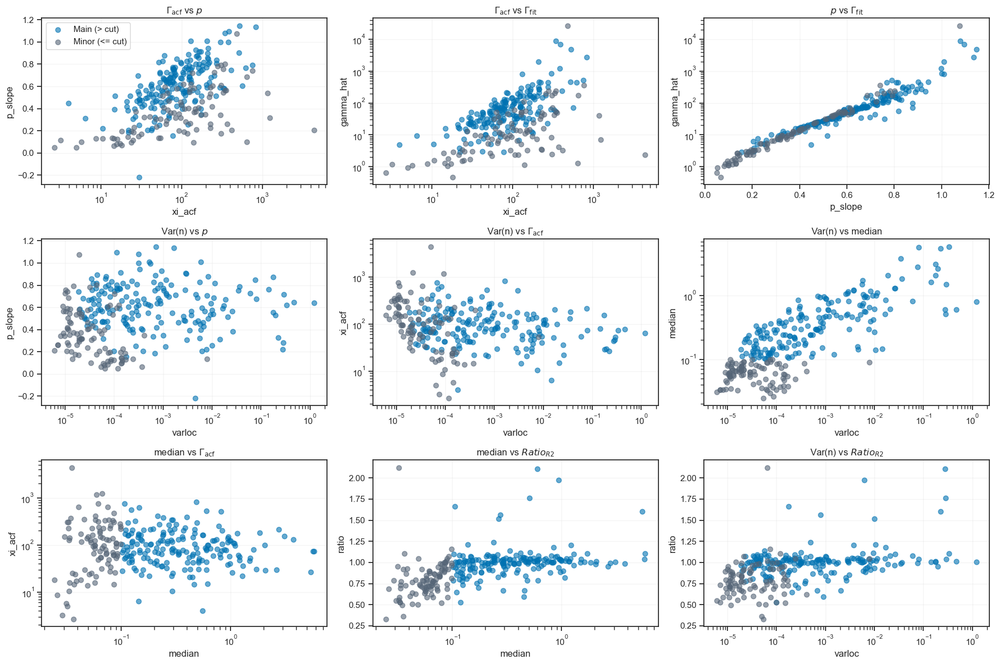

In [28]:
thr = 10 / 100  

df_clean['group'] = np.where(df_clean['median'] > thr, 'Main (> cut)', 'Minor (<= cut)')

df_main = df_clean[df_clean['median'] > thr].copy()
df_minor = df_clean[df_clean['median'] <= thr].copy()

print(f"MAIN (median > cut):  {len(df_main)}")
print(f"MINOR (median <= cut): {len(df_minor)}")
print(f"Total: {len(df_clean)}")
scatter_panels = [
    ('xi_acf', 'p_slope', r'$\Gamma_{\mathrm{acf}}$ vs $p$'),
    ('xi_acf', 'gamma_hat', r'$\Gamma_{\mathrm{acf}}$ vs $\Gamma_\mathrm{fit}$'),
    ('p_slope', 'gamma_hat', r'$p$ vs $\Gamma_\mathrm{fit}$'),
    ('varloc', 'p_slope', r'Var(n) vs $p$'),
    ('varloc', 'xi_acf', r'Var(n) vs $\Gamma_{\mathrm{acf}}$'),
    ('varloc', 'median', r'Var(n) vs median'),
    ('median', 'xi_acf', r'median vs $\Gamma_{\mathrm{acf}}$'),
    ('median', 'ratio', r'median vs $Ratio_{R2}$'),
    ('varloc', 'ratio', r'Var(n) vs $Ratio_{R2}$')
]

color_map = {
    'Main (> cut)': c_main,  
    'Minor (<= cut)': c_second  
}

plt.figure(figsize=(18,12))
for i, (xcol, ycol, title) in enumerate(scatter_panels, 1):
    plt.subplot(3,3,i)
    

    for group_name, color in color_map.items():
        subset = df_clean[df_clean['group'] == group_name]
        plt.scatter(subset[xcol], subset[ycol], color=color, alpha=0.6, s=40, label=group_name)
    

    if xcol in ['xi_acf', 'varloc', 'median', 'gamma_hat', 'v_hat']:
        plt.xscale('log')
    if ycol in ['xi_acf', 'varloc', 'median', 'gamma_hat', 'v_hat']:
        plt.yscale('log')
    
    plt.xlabel(xcol)
    plt.ylabel(ycol)
    plt.title(title)
    plt.grid(alpha=0.2)
    
    if i == 1:
        plt.legend(loc='best')

plt.tight_layout()
plt.show()

Geographic distribution of the 2 clusters

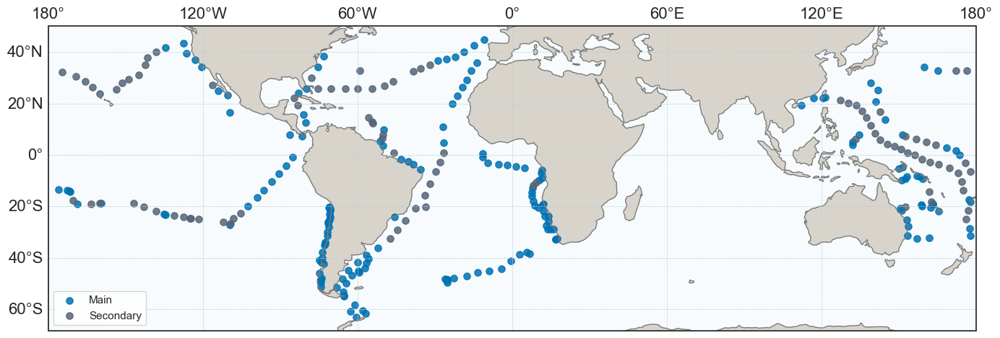

In [29]:
MAP_OCEAN = "#F7FBFD"
MAP_LAND = "#D8D4CC"
MAP_COAST = "#7A7A7A"
MAP_GRID = "#B9CBD2"

projection = ccrs.PlateCarree(central_longitude=0)
fig, ax = plt.subplots(figsize=(14, 6), subplot_kw=dict(projection=projection))


ax.set_facecolor(MAP_OCEAN)
ax.add_feature(cfeature.LAND, facecolor=MAP_LAND)
ax.add_feature(cfeature.COASTLINE, edgecolor=MAP_COAST)


gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                  linewidth=0.5, color=MAP_GRID, linestyle='--')


gl.top_labels = True
gl.bottom_labels = False
gl.left_labels = True
gl.right_labels = False 


gl.xlabel_style = {'size': 16}
gl.ylabel_style = {'size': 16}
ax.scatter(df_main['lon'], df_main['lat'], transform=ccrs.PlateCarree(),
                             color=c_main, s=45, alpha=0.85, label='Main')

ax.scatter(df_minor['lon'], df_minor['lat'], transform=ccrs.PlateCarree(),
                                        color=c_second, s=45, alpha=0.85, label='Secondary')



style_figure_axis(ax)
plt.legend(loc='lower left', frameon=True)
plt.tight_layout()
plt.show()

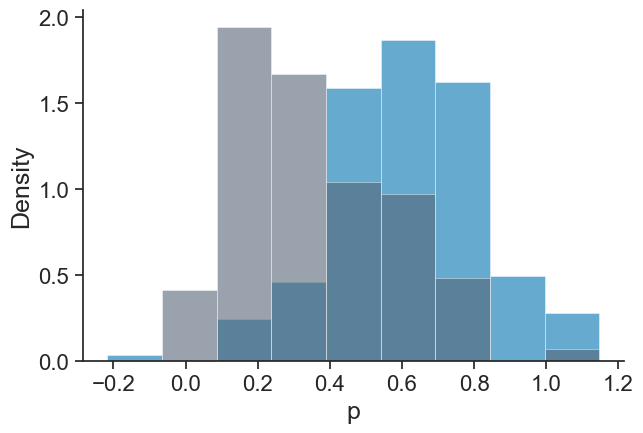

In [30]:
min_val = min(df_main['p_slope'].min(), df_minor['p_slope'].min())
max_val = max(df_main['p_slope'].max(), df_minor['p_slope'].max())
bins = np.linspace(min_val, max_val, 10)


fig, ax = plt.subplots(figsize=(6.5, 4.5))


ax.hist(df_main['p_slope'], bins=bins, density=True, 
        color=c_main, alpha=0.6, label='Main', edgecolor='white', linewidth=0.5)

ax.hist(df_minor['p_slope'], bins=bins, density=True, 
        color=c_second, alpha=0.6, label='Minor', edgecolor='white', linewidth=0.5)


ax.set(xlabel="p", ylabel="Density")
style_figure_axis(ax) 


sns.despine(ax=ax)
#plt.legend(frameon=False)
ax.grid(False)
plt.tight_layout()

plt.show()

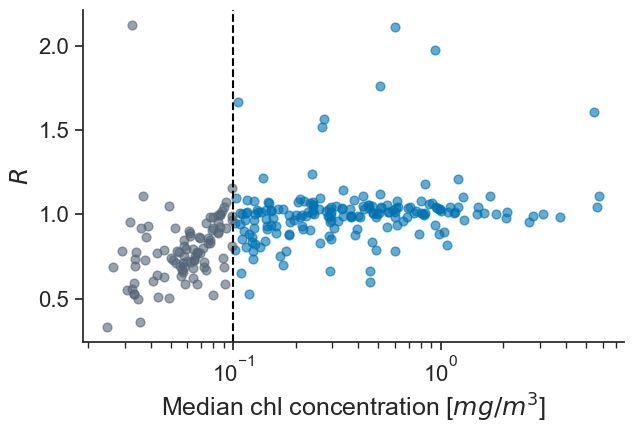

In [31]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))


ax.scatter(df_main["median"], df_main["ratio"], 
           color=c_main, alpha=0.6, s=40, label='Main')

ax.scatter(df_minor["median"], df_minor["ratio"], 
           color=c_second, alpha=0.6, s=40, label='Secondary')


ax.set_xscale('log')

ax.axvline(x=0.1, color='black', linestyle='--', linewidth=1.5)
ax.set(xlabel="Median chl concentration [$mg/m^3$]", ylabel=r"$R$")
style_figure_axis(ax)
ax.grid(False)
sns.despine(ax=ax)
#plt.legend(frameon=False)
plt.tight_layout()
plt.show()

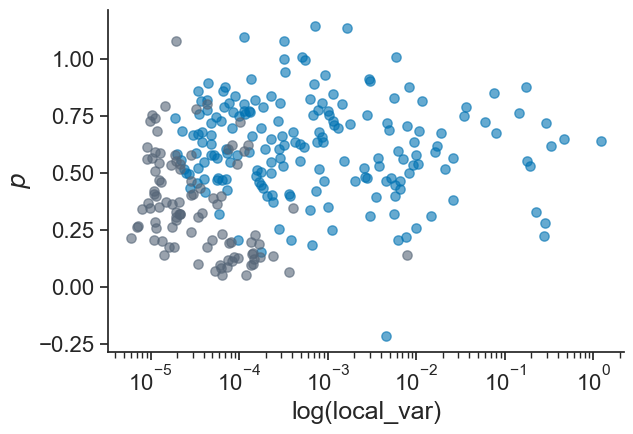

In [32]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))


ax.scatter(df_main["varloc"], df_main["p_slope"], 
           color=c_main, alpha=0.6, s=45, label='Main')

ax.scatter(df_minor["varloc"], df_minor["p_slope"], 
           color=c_second, alpha=0.6, s=45, label='Secondary')



ax.set(xlabel="log(local_var)", ylabel=r"$p$")
ax.set(xscale='log')
style_figure_axis(ax)
ax.grid(False)
sns.despine(ax=ax)
#plt.legend(frameon=False)
plt.tight_layout()
plt.show()

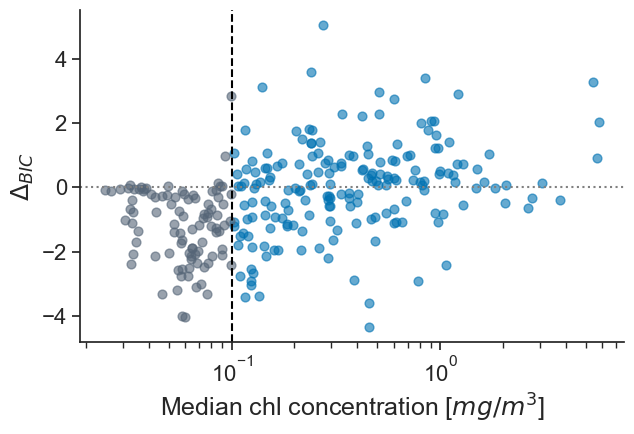

In [34]:
df_main["Delta_ll"] = df_main["ll_pat"] - df_main["ll_linear"]
df_minor["Delta_ll"] = df_minor["ll_pat"] - df_minor["ll_linear"]

fig, ax = plt.subplots(figsize=(6.5, 4.5))


ax.scatter(df_main["median"], 2*df_main["Delta_ll"], 
           color=c_main, alpha=0.6, s=40, label='Main')

ax.scatter(df_minor["median"], 2*df_minor["Delta_ll"], 
           color=c_second, alpha=0.6, s=40, label='Secondary')

ax.set_xscale('log')

ax.axvline(x=0.1, color='black', linestyle='--', linewidth=1.5)

ax.axhline(y=0, color='gray', linestyle=':', linewidth=1.5)

ax.set(xlabel="Median chl concentration [$mg/m^3$]", ylabel=r"$\Delta_{BIC}$")

style_figure_axis(ax)
ax.grid(False)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

Mean Delta BIC for Main cluster: 0.10
Mean Delta BIC for Secondary cluster: -1.03


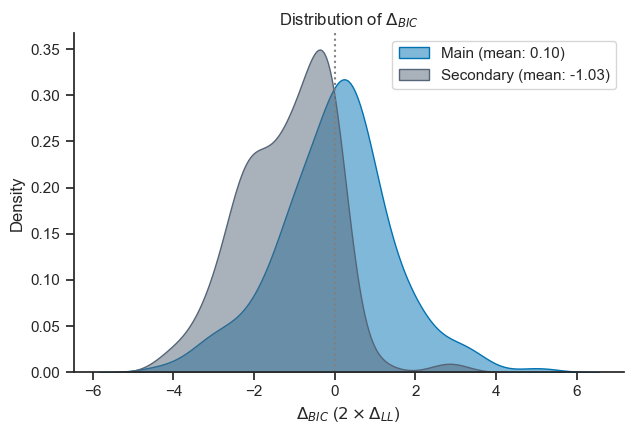

In [35]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))

delta_bic_main = 2 * df_main["Delta_ll"]
delta_bic_minor = 2 * df_minor["Delta_ll"]

mean_main = delta_bic_main.median()
mean_minor = delta_bic_minor.median()

print(f"Mean Delta BIC for Main cluster: {mean_main:.2f}")
print(f"Mean Delta BIC for Secondary cluster: {mean_minor:.2f}")

sns.kdeplot(data=delta_bic_main, fill=True, color=c_main, alpha=0.5, 
            label=f'Main (mean: {mean_main:.2f})', ax=ax)
sns.kdeplot(data=delta_bic_minor, fill=True, color=c_second, alpha=0.5, 
            label=f'Secondary (mean: {mean_minor:.2f})', ax=ax)

ax.axvline(x=0, color='gray', linestyle=':', linewidth=1.5)

ax.set(xlabel=r"$\Delta_{BIC}$ ($2 \times \Delta_{LL}$)", ylabel="Density")
ax.set_title(r"Distribution of $\Delta_{BIC}$")

ax.grid(False)
sns.despine(ax=ax)
ax.legend()

plt.tight_layout()
plt.show()

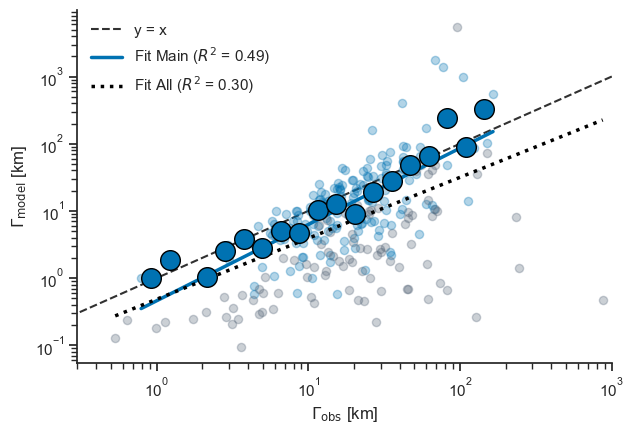

In [36]:
mask_main = (df_main["xi_acf"] > 0) & (df_main["gamma_hat"] > 0) & \
            (df_main["xi_acf"].notna()) & (df_main["gamma_hat"].notna())
df_main_valid = df_main[mask_main]

x_main_lin = df_main_valid["xi_acf"] * 0.2
y_main_lin = df_main_valid["gamma_hat"] * 0.2

res_main = linregress(np.log10(x_main_lin), np.log10(y_main_lin))
r2_main = res_main.rvalue ** 2

mask_all = (df_clean["xi_acf"] > 0) & (df_clean["gamma_hat"] > 0) & \
           (df_clean["xi_acf"].notna()) & (df_clean["gamma_hat"].notna())
df_clean_valid = df_clean[mask_all]

x_all_lin = df_clean_valid["xi_acf"] * 0.2
y_all_lin = df_clean_valid["gamma_hat"] * 0.2

res_all = linregress(np.log10(x_all_lin), np.log10(y_all_lin))
r2_all = res_all.rvalue ** 2


fig, ax = plt.subplots(figsize=(6.5, 4.5))

ax.scatter(df_main["xi_acf"] * 0.2, df_main["gamma_hat"] * 0.2, 
           color=c_main, alpha=0.3, s=35)
ax.scatter(df_minor["xi_acf"] * 0.2, df_minor["gamma_hat"] * 0.2, 
           color=c_second, alpha=0.3, s=35)

bins = np.logspace(np.log10(np.min(df_main["xi_acf"] * 0.2)), np.log10(np.max(df_main["xi_acf"] * 0.2)), 20)
bin_centers = (bins[:-1] + bins[1:]) / 2

med_main, _, _ = binned_statistic(df_main["xi_acf"] * 0.2, df_main["gamma_hat"] * 0.2, 
                                  statistic='median', bins=bins)
ax.scatter(bin_centers, med_main, color=c_main, s=200, edgecolors='black', zorder=10)

lims = [np.min([ax.get_xlim(), ax.get_ylim()]), np.max([ax.get_xlim(), ax.get_ylim()])]
ax.plot(lims, lims, 'k--', alpha=0.9, zorder=0, label='y = x')

fit_x_main = np.array([np.min(x_main_lin), np.max(x_main_lin)])
fit_y_main = 10 ** (res_main.intercept + res_main.slope * np.log10(fit_x_main))
ax.plot(fit_x_main, fit_y_main, color=c_main, lw=2.5, 
        label=f'Fit Main ($R^2$ = {r2_main:.2f})')


fit_x_all = np.array([np.min(x_all_lin), np.max(x_all_lin)])
fit_y_all = 10 ** (res_all.intercept + res_all.slope * np.log10(fit_x_all))
ax.plot(fit_x_all, fit_y_all, color='black', lw=2.5, linestyle=':', 
        label=f'Fit All ($R^2$ = {r2_all:.2f})')

ax.set_xscale('log')
ax.set_yscale('log')

ax.set(xlabel=r"$\Gamma_{\mathrm{obs}}$ [km]", ylabel=r"$\Gamma_{\mathrm{model}}$ [km]")
ax.set_xlim([3/10, 1000])

ax.grid(False)
sns.despine(ax=ax)

ax.legend(loc='upper left', frameon=False)

plt.tight_layout()
plt.show()

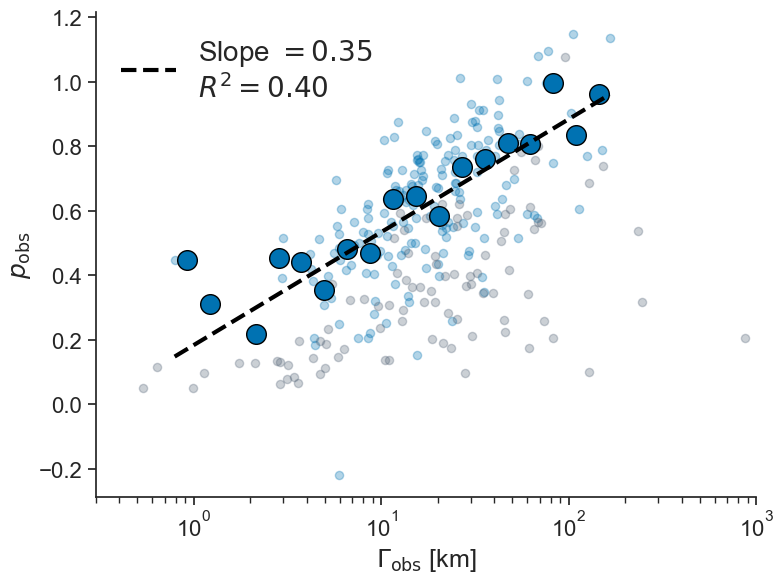

In [37]:
fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(df_main["xi_acf"] * 0.2, df_main["p_slope"], 
           color=c_main, alpha=0.3, s=35)
ax.scatter(df_minor["xi_acf"] * 0.2, df_minor["p_slope"], 
           color=c_second, alpha=0.3, s=35)

bins = np.logspace(np.log10(np.min(df_main["xi_acf"] * 0.2)), np.log10(np.max(df_main["xi_acf"] * 0.2)), 20)
bin_centers = (bins[:-1] + bins[1:]) / 2

med_main, _, _ = binned_statistic(df_main["xi_acf"] * 0.2,df_main["p_slope"], 
                                  statistic='median', bins=bins)


from scipy.stats import linregress

x_main = df_main["xi_acf"] * 0.2
y_main = df_main["p_slope"]
log_x_main = np.log10(x_main)

slope, intercept, r_value, p_value, std_err = linregress(log_x_main, y_main)

x_fit = np.logspace(np.log10(x_main.min()), np.log10(x_main.max()), 100)
y_fit = intercept + slope * np.log10(x_fit)


ax.plot(x_fit, y_fit, color='black', linestyle='--', linewidth=3, zorder=15, 
        label=rf'Slope $= {slope:.2f}$' + '\n' + rf'$R^2={r_value**2:.2f}$')
ax.legend(frameon=False, loc='best', fontsize=20)



ax.scatter(bin_centers, med_main, color=c_main, s=200, edgecolors='black', zorder=10)


ax.set_xscale('log')
#ax.set_yscale('log')

ax.set(xlabel=r"$\Gamma_{\mathrm{obs}}$ [km]", ylabel=r"$p_{\mathrm{obs}}$")
ax.set_xlim([3/10,1000])
style_figure_axis(ax)
ax.grid(False)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

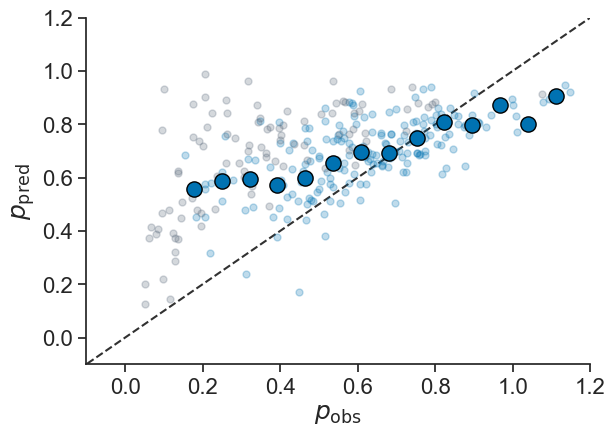

In [38]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))

ax.scatter(df_main["p_slope"] , df_main["p_theoretical"] , 
           color=c_main, alpha=0.25, s=25)
ax.scatter(df_minor["p_slope"], df_minor["p_theoretical"], 
           color=c_second, alpha=0.25, s=25)

bins = np.linspace(np.min(df_main["p_slope"]), np.max(df_main["p_slope"]), 20)
bin_centers = (bins[:-1] + bins[1:]) / 2

med_main, _, _ = binned_statistic(df_main["p_slope"] , df_main["p_theoretical"], 
                                  statistic='median', bins=bins)


ax.scatter(bin_centers, med_main, color=c_main, s=120, edgecolors='black', zorder=10)


lims = [np.min([ax.get_xlim(), ax.get_ylim()]), np.max([ax.get_xlim(), ax.get_ylim()])]
ax.plot(lims, lims, 'k--', alpha=0.9, zorder=0)


ax.set(xlabel=r"$p_{\mathrm{obs}}$", ylabel=r"$p_{\mathrm{pred}}$")
ax.set_xlim([-0.1,1.2])
ax.set_ylim([-0.1,1.2])
style_figure_axis(ax)
ax.grid(False)
sns.despine(ax=ax)

#plt.tight_layout()
plt.show()

# Total biomass distribution




In [ ]:
step = 1500
num_bins = 10 
n_cols = 6

valid_block_indices = df_plot.index.values 

num_plots = len(valid_block_indices)
n_rows = int(np.ceil(num_plots / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 4, n_rows * 3.5))
axes = axes.flatten() 

plot_counter = 0

for block_idx in valid_block_indices:
    ax = axes[plot_counter]

    df_subset = gdf.iloc[block_idx * step : (block_idx + 1) * step]
    chla = df_subset["Chl_lineheight"].dropna().values
    
    chla = chla[chla > 0]
    
    if len(chla) < 10:
        ax.text(0.5, 0.5, 'Insufficient Data', ha='center', va='center', color='gray')
        ax.axis('off')
        plot_counter += 1
        continue
        
    mean_lat = df_subset["lat"].mean()
    mean_lon = df_subset["lon"].mean()
    
    bins = np.logspace(np.log10(chla.min()), np.log10(chla.max()), num_bins + 1)
    hist, bin_edges = np.histogram(chla, bins=bins, density=True)
    centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])
    

    mean_chla = np.mean(chla)
    var_chla = np.var(chla)
    sigma_log = np.sqrt(np.log(1 + (var_chla / (mean_chla ** 2))))
    mu_log = np.log(mean_chla) - 0.5 * (sigma_log ** 2)

    xgrid = np.logspace(np.log10(chla.min()), np.log10(chla.max()), 200)
    pdf_ln = lognorm.pdf(xgrid, s=sigma_log, scale=np.exp(mu_log))
    

    ax.set_xscale('log')
    ax.set_yscale('log')
    
    ax.scatter(centers, hist, s=60, color='#2b2b2b', alpha=0.8, edgecolors='none', label='Data' if plot_counter==0 else "")
    ax.plot(xgrid, pdf_ln, color='#1a9615', lw=2.5, linestyle='--', label='Lognormal' if plot_counter==0 else "")

    ax.set_xlim((chla.min() * 0.85, chla.max() * 1.15))
    
    valid_hist = hist[hist > 0]
    if len(valid_hist) > 0:
        min_y = min(valid_hist.min(), pdf_ln.min())
        max_y = max(valid_hist.max(), pdf_ln.max())
        ax.set_ylim((min_y * 0.5, max_y * 2.0))
    
    ax.grid(which='both', linestyle='--', alpha=0.3)
    ax.set_title(f"Lat: {mean_lat:.2f}°\nLon: {mean_lon:.2f}°", fontsize=10, fontweight='bold')
    
    ax.set_ylabel("PDF", fontsize=10)
    ax.set_xlabel("Chl [mg/m³]", fontsize=10)
        
    ax.tick_params(axis='both', which='major', labelsize=10)
    
    plot_counter += 1


for blank_ax in range(plot_counter, len(axes)):
    axes[blank_ax].axis('off')

axes[0].legend(frameon=False, fontsize=10, loc='upper right')

plt.tight_layout()
plt.show()

In [42]:

mask_valid = (
    df_plot['delta_bic'].notna() 
)
df_valid = df_plot[mask_valid].copy()

tot = len(df_valid)
lin_wins = (df_valid['delta_bic'] < -5).sum()
uncertain = (df_valid['delta_bic'].abs() <= 5).sum()
pat_wins = (df_valid['delta_bic'] > 5).sum()

print(f"Total: {tot}")
if tot > 0:
    print(f"LNM (Delta < -5): {lin_wins} ({(lin_wins/tot)*100:.1f}%)")
    print(f"Equivalent (|Delta| <= 5): {uncertain} ({(uncertain/tot)*100:.1f}%)")
    print(f"GIG (Delta > 5): {pat_wins} ({(pat_wins/tot)*100:.1f}%)")
else:
    print("Error.")

Total: 280
LNM (Delta < -5): 233 (83.2%)
Equivalent (|Delta| <= 5): 2 (0.7%)
GIG (Delta > 5): 45 (16.1%)


Text(0, 0.5, 'pdf')

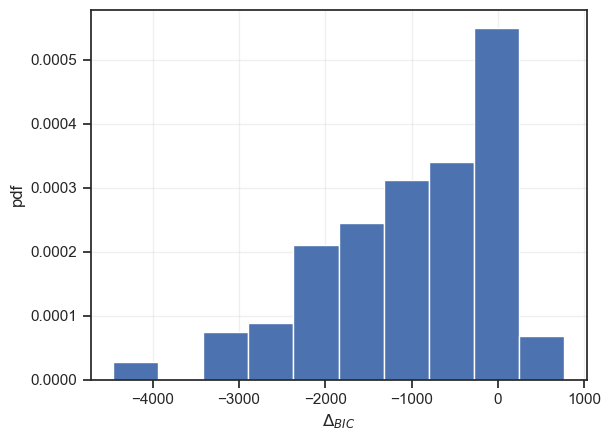

In [299]:
plt.hist(df_valid['delta_bic'], density = True)
plt.xlabel(r'$\Delta_{BIC}$')
plt.ylabel('pdf')

# Pathciness analysis using 'patch' function

In [ ]:
n_plots = len(df_plot)
cols = 6  
rows = math.ceil(n_plots / cols)

win_sizes = np.unique(np.logspace(np.log10(5), np.log10(1500), 16, dtype=int))
var_cols = [f"var_win_{win}" for win in win_sizes]


fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 5 * rows))

if n_plots == 1:
    axes = np.array([axes])
axes = axes.flatten()

for i, (idx, row) in enumerate(df_plot.iterrows()):
    ax = axes[i]
    
    # Variance
    var_vals = row[var_cols].values.astype(float)
    mask = np.isfinite(var_vals) & (var_vals > 0)
    
    if np.sum(mask) < 2:
        ax.set_title(f"Idx {idx}: Not enough data")
        continue

    # linear fit in log log scale
    slope_real = row['p_slope'] 
    intercept_real = np.polyfit(np.log(win_sizes[mask]), np.log(var_vals[mask]), 1)[1]
    y_fit_linear = slope_real * np.log(win_sizes) + intercept_real

    # patch fit
    gamma_hat = row['gamma_hat'] 
    v_hat = row['v_hat']
    y_fit_patch = np.log(patch(win_sizes, gamma_hat, v_hat))

    # plot
    ax.scatter(np.log(win_sizes), np.log(var_vals), s=80, color='#2b2b2b', 
               alpha=0.8, edgecolors='none', label='Data')

    # Vertical line: 2 Gamma
    xi_val = row['xi_acf'] * 2
    if np.isfinite(xi_val) and xi_val > 0:
        ax.axvline(np.log(xi_val), color='black', linestyle=':', lw=2, label=r'$2\,\Gamma_\mathrm{ACF}$')

    # Linee di fit
    ax.plot(np.log(win_sizes), y_fit_linear, color="#1a9615", lw=2.5, linestyle='--', label=r'$L^p$')
    ax.plot(np.log(win_sizes), y_fit_patch, color='#ff7f0e', lw=2.5, linestyle='-', label='Model')

    # coordinates
    lat, lon = row['lat'], row['lon']
    r2_lin = row['R2lin']
    r2_pat = row['R2pat']
    
    if np.isfinite(r2_lin) and r2_lin != 0 and np.isfinite(r2_pat):
        r2_ratio = r2_pat / r2_lin
        ratio_str = f"{r2_ratio:.2f}"
    else:
        ratio_str = "N/A"

    text_info = (f"Lat: {lat:.2f}°, Lon: {lon:.2f}°\n"
                 f"$R^2_{{pat}} / R^2_{{lin}}$: {ratio_str}")
    
    
    ax.text(0.05, 0.95, text_info, transform=ax.transAxes, fontsize=12,
            verticalalignment='top', bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.8))

  
    ax.set_xlabel(r'$\log(L)$', fontsize=14)
    ax.set_ylabel(r'$\log(\mathrm{Var}(n|L))$', fontsize=14)
    ax.tick_params(axis='both', which='major', labelsize=12)
    ax.grid(alpha=0.3, linestyle='--')

    if i == 0:
        ax.legend(frameon=False, fontsize=11, loc='lower right')


for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()